In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

features = pd.read_csv("data/elliptic_txs_features.csv", header=None)
classes = pd.read_csv("data/elliptic_txs_classes.csv")

# Column 0 = txId, column 1 = time step, columns 2..166 = the 165 features
feat_cols = [f"f{i}" for i in range(2, 167)]
features.columns = ["txId", "time_step"] + feat_cols

df = features.merge(classes, on="txId")

# Keep labeled rows only; illicit (class "1") is the positive class
df = df[df["class"] != "unknown"].copy()
df["y"] = (df["class"] == "1").astype(int)

train = df[df["time_step"] <= 34]
test = df[df["time_step"] >= 35]

X_train, y_train = train[feat_cols], train["y"]
X_test, y_test = test[feat_cols], test["y"]

print(len(train), len(test))
print("illicit share train/test:", y_train.mean().round(3), y_test.mean().round(3))

29894 16670
illicit share train/test: 0.116 0.065


In [2]:
rf = RandomForestClassifier(n_estimators=50, max_features=50,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:   ", round(recall_score(y_test, pred), 3))
print("Illicit F1:", round(f1_score(y_test, pred), 3))

Precision: 0.914
Recall:    0.724
Illicit F1: 0.808


    time_step  n_illicit  precision  recall     f1
0          35        182      0.978   0.956  0.967
1          36         33      0.868   1.000  0.930
2          37         40      0.963   0.650  0.776
3          38        111      0.990   0.901  0.943
4          39         81      0.904   0.926  0.915
5          40        112      0.926   0.670  0.777
6          41        116      0.991   0.922  0.955
7          42        239      0.955   0.799  0.870
8          43         24      0.000   0.000  0.000
9          44         24      0.077   0.042  0.054
10         45          5      0.000   0.000  0.000
11         46          2      0.125   0.500  0.200
12         47         22      0.000   0.000  0.000
13         48         36      0.000   0.000  0.000
14         49         56      0.250   0.018  0.033


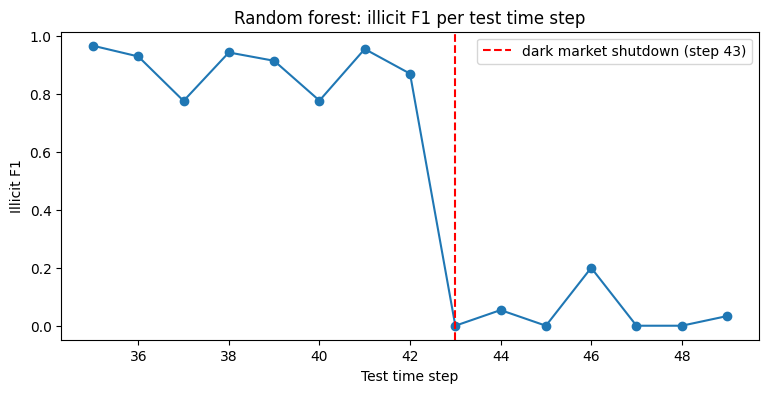

In [3]:
rows = []
for t in range(35, 50):
    m = test["time_step"] == t
    yt, yp = y_test[m], pred[m.values]
    rows.append({
        "time_step": t,
        "n_illicit": int(yt.sum()),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0),
        "f1": f1_score(yt, yp, zero_division=0),
    })

per_step = pd.DataFrame(rows)
print(per_step.round(3))

plt.figure(figsize=(9, 4))
plt.plot(per_step["time_step"], per_step["f1"], marker="o")
plt.axvline(43, color="red", linestyle="--", label="dark market shutdown (step 43)")
plt.xlabel("Test time step")
plt.ylabel("Illicit F1")
plt.title("Random forest: illicit F1 per test time step")
plt.legend()
plt.show()

import os
os.makedirs("results", exist_ok=True)
per_step.to_csv("results/rf_baseline_per_step.csv", index=False)

In [4]:
test = test.copy()
test["p_illicit"] = rf.predict_proba(X_test)[:, 1]
test["pred"] = pred

rows = []
for t in range(35, 50):
    m = test["time_step"] == t
    rows.append({
        "time_step": t,
        "n_pred_illicit": int(test.loc[m, "pred"].sum()),
        "mean_p_true_illicit": test.loc[m & (test["y"] == 1), "p_illicit"].mean(),
        "mean_p_licit": test.loc[m & (test["y"] == 0), "p_illicit"].mean(),
    })

prob_summary = pd.DataFrame(rows)
print(prob_summary.round(3))
prob_summary.to_csv("results/rf_probability_summary.csv", index=False)

    time_step  n_pred_illicit  mean_p_true_illicit  mean_p_licit
0          35             178                0.943         0.049
1          36              38                0.947         0.060
2          37              27                0.639         0.040
3          38             101                0.881         0.055
4          39              83                0.887         0.063
5          40              81                0.658         0.088
6          41             108                0.881         0.076
7          42             200                0.795         0.072
8          43               5                0.103         0.091
9          44              13                0.146         0.112
10         45              10                0.140         0.096
11         46               8                0.470         0.079
12         47               2                0.064         0.067
13         48               0                0.050         0.053
14         49            

In [5]:
from sklearn.metrics import roc_auc_score

rows = []
for t in range(35, 50):
    m = test["time_step"] == t
    rows.append({
        "time_step": t,
        "auc": roc_auc_score(test.loc[m, "y"], test.loc[m, "p_illicit"]),
    })

auc_by_step = pd.DataFrame(rows)
print(auc_by_step.round(3))
auc_by_step.to_csv("results/rf_auc_by_step.csv", index=False)

    time_step    auc
0          35  0.995
1          36  1.000
2          37  0.937
3          38  0.987
4          39  0.986
5          40  0.884
6          41  0.982
7          42  0.943
8          43  0.586
9          44  0.585
10         45  0.674
11         46  0.856
12         47  0.594
13         48  0.557
14         49  0.598


In [6]:
pre = test[test["time_step"] <= 42]
post = test[test["time_step"] >= 43]
print("Pooled AUC steps 35-42:", round(roc_auc_score(pre["y"], pre["p_illicit"]), 3))
print("Pooled AUC steps 43-49:", round(roc_auc_score(post["y"], post["p_illicit"]), 3))

Pooled AUC steps 35-42: 0.965
Pooled AUC steps 43-49: 0.53


q illicit: 0.44  q licit: 0.04
    time_step  n_illicit  cov_illicit  cov_licit  avg_set_size  frac_empty
0          35        182        0.951      0.748         0.779       0.221
1          36         33        0.939      0.750         0.755       0.245
2          37         40        0.625      0.788         0.781       0.219
3          38        111        0.883      0.687         0.718       0.282
4          39         81        0.926      0.744         0.759       0.241
5          40        112        0.670      0.516         0.538       0.462
6          41        116        0.922      0.587         0.621       0.379
7          42        239        0.791      0.643         0.669       0.331
8          43         24        0.000      0.411         0.407       0.593
9          44         24        0.042      0.486         0.487       0.513
10         45          5        0.000      0.590         0.593       0.407
11         46          2        0.500      0.680         0.684       

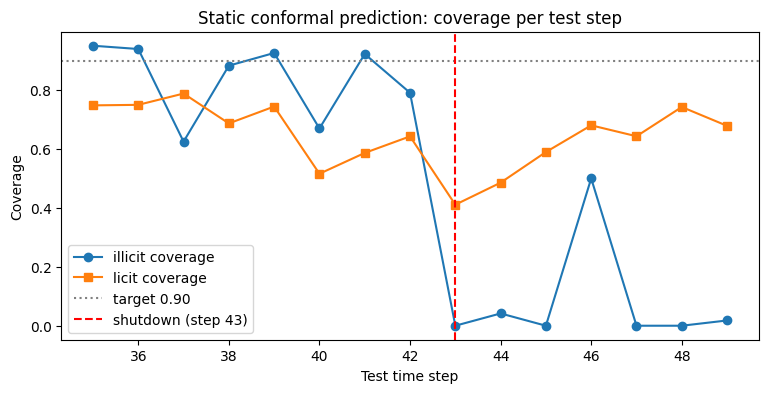

In [7]:
from sklearn.model_selection import train_test_split

# 1. Split steps 1-34 into fit and calibration sets
tr_fit, tr_cal = train_test_split(
    train, test_size=0.25, stratify=train["y"], random_state=42
)

rf2 = RandomForestClassifier(n_estimators=50, max_features=50,
                             random_state=42, n_jobs=-1)
rf2.fit(tr_fit[feat_cols], tr_fit["y"])

cal_p = rf2.predict_proba(tr_cal[feat_cols])[:, 1]
cal_y = tr_cal["y"].values

# 2. Class-conditional conformal thresholds
alpha = 0.1

def conformal_q(scores, alpha):
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method="higher")

q1 = conformal_q(1 - cal_p[cal_y == 1], alpha)  # illicit score = 1 - p_illicit
q0 = conformal_q(cal_p[cal_y == 0], alpha)      # licit score = p_illicit
print("q illicit:", round(q1, 3), " q licit:", round(q0, 3))

# 3. Prediction sets on the test period
test = test.copy()
test["p2"] = rf2.predict_proba(test[feat_cols])[:, 1]
test["in_set_illicit"] = (1 - test["p2"]) <= q1
test["in_set_licit"] = test["p2"] <= q0
test["set_size"] = test["in_set_illicit"].astype(int) + test["in_set_licit"].astype(int)

# 4. Coverage and set size per test step
rows = []
for t in range(35, 50):
    d = test[test["time_step"] == t]
    ill, lic = d[d["y"] == 1], d[d["y"] == 0]
    rows.append({
        "time_step": t,
        "n_illicit": len(ill),
        "cov_illicit": ill["in_set_illicit"].mean(),
        "cov_licit": lic["in_set_licit"].mean(),
        "avg_set_size": d["set_size"].mean(),
        "frac_empty": (d["set_size"] == 0).mean(),
    })
conf = pd.DataFrame(rows)
print(conf.round(3))
conf.to_csv("results/conformal_static_per_step.csv", index=False)

# 5. Plot
plt.figure(figsize=(9, 4))
plt.plot(conf["time_step"], conf["cov_illicit"], marker="o", label="illicit coverage")
plt.plot(conf["time_step"], conf["cov_licit"], marker="s", label="licit coverage")
plt.axhline(1 - alpha, color="gray", linestyle=":", label="target 0.90")
plt.axvline(43, color="red", linestyle="--", label="shutdown (step 43)")
plt.xlabel("Test time step")
plt.ylabel("Coverage")
plt.title("Static conformal prediction: coverage per test step")
plt.legend()
plt.show()

In [8]:
fit_t = train[train["time_step"] <= 24]
cal_t = train[train["time_step"] >= 25]

rf3 = RandomForestClassifier(n_estimators=50, max_features=50,
                             random_state=42, n_jobs=-1)
rf3.fit(fit_t[feat_cols], fit_t["y"])

cal_p3 = rf3.predict_proba(cal_t[feat_cols])[:, 1]
cal_y3 = cal_t["y"].values
q1_t = conformal_q(1 - cal_p3[cal_y3 == 1], alpha)
q0_t = conformal_q(cal_p3[cal_y3 == 0], alpha)
print("q illicit:", round(q1_t, 3), " q licit:", round(q0_t, 3))

test["p3"] = rf3.predict_proba(test[feat_cols])[:, 1]
test["ill3"] = (1 - test["p3"]) <= q1_t
test["lic3"] = test["p3"] <= q0_t

def pooled(d, ill_col, lic_col):
    ill, lic = d[d["y"] == 1], d[d["y"] == 0]
    empty = (~d[ill_col] & ~d[lic_col]).mean()
    return {"illicit_cov": round(ill[ill_col].mean(), 3),
            "licit_cov": round(lic[lic_col].mean(), 3),
            "empty": round(empty, 3)}

pre = test[test["time_step"] <= 42]
post = test[test["time_step"] >= 43]

for name, (a, b) in {"random cal split": ("in_set_illicit", "in_set_licit"),
                     "temporal cal split": ("ill3", "lic3")}.items():
    print(name, "| steps 35-42:", pooled(pre, a, b))
    print(name, "| steps 43-49:", pooled(post, a, b))

q illicit: 0.46  q licit: 0.2
random cal split | steps 35-42: {'illicit_cov': np.float64(0.846), 'licit_cov': np.float64(0.677), 'empty': np.float64(0.303)}
random cal split | steps 43-49: {'illicit_cov': np.float64(0.018), 'licit_cov': np.float64(0.56), 'empty': np.float64(0.442)}
temporal cal split | steps 35-42: {'illicit_cov': np.float64(0.792), 'licit_cov': np.float64(0.831), 'empty': np.float64(0.162)}
temporal cal split | steps 43-49: {'illicit_cov': np.float64(0.018), 'licit_cov': np.float64(0.802), 'empty': np.float64(0.197)}


In [9]:
def aci_threshold(scores, a_t):
    if a_t <= 0:
        return np.inf        # include "illicit" in every set
    if a_t >= 1:
        return -np.inf       # include it in no set
    return np.quantile(scores, 1 - a_t, method="higher")

cal_s_ill = 1 - cal_p3[cal_y3 == 1]   # illicit scores from the calibration window

def run_aci(test, gamma=0.005, alpha=0.1, delay=0):
    a_t = alpha
    pending, rows = {}, []
    for t in range(35, 50):
        d = test[test["time_step"] == t]
        thr = aci_threshold(cal_s_ill, a_t)
        flagged = (1 - d["p3"].values) <= thr      # set contains "illicit"
        y = d["y"].values
        pending[t] = (~flagged[y == 1]).astype(int)  # 1 = illicit transaction missed
        rows.append({"time_step": t, "alpha_t": a_t, "n_tx": len(d),
                     "n_illicit": int((y == 1).sum()),
                     "cov_illicit": float(flagged[y == 1].mean()),
                     "flag_rate": float(flagged.mean())})
        if (t - delay) in pending:                  # feedback arrives after `delay` steps
            for e in pending[t - delay]:
                a_t = a_t + gamma * (alpha - e)
    return pd.DataFrame(rows)

def pooled_aci(res, lo, hi):
    r = res[res["time_step"].between(lo, hi)]
    cov = np.average(r["cov_illicit"], weights=r["n_illicit"])
    flag = np.average(r["flag_rate"], weights=r["n_tx"])
    return round(float(cov), 3), round(float(flag), 3)

out = []
for gamma in [0.0, 0.005, 0.01, 0.02]:
    for delay in [0, 1, 3]:
        if gamma == 0 and delay > 0:
            continue
        res = run_aci(test, gamma=gamma, delay=delay)
        c1, f1 = pooled_aci(res, 35, 42)
        c2, f2 = pooled_aci(res, 43, 49)
        out.append({"gamma": gamma, "delay": delay,
                    "cov_35_42": c1, "flag_35_42": f1,
                    "cov_43_49": c2, "flag_43_49": f2})

grid = pd.DataFrame(out)
print(grid)
grid.to_csv("results/aci_grid.csv", index=False)

res = run_aci(test, gamma=0.005, delay=0)
print(res.round(3))
res.to_csv("results/aci_gamma005_delay0.csv", index=False)

   gamma  delay  cov_35_42  flag_35_42  cov_43_49  flag_43_49
0  0.000      0      0.792       0.074      0.018       0.004
1  0.005      0      0.896       0.388      0.799       0.750
2  0.005      1      0.876       0.179      0.858       0.796
3  0.005      3      0.848       0.149      1.000       0.981
4  0.010      0      0.902       0.444      0.858       0.795
5  0.010      1      0.867       0.402      0.858       0.795
6  0.010      3      0.873       0.374      1.000       1.000
7  0.020      0      0.868       0.277      1.000       1.000
8  0.020      1      0.862       0.402      0.858       0.795
9  0.020      3      0.873       0.374      1.000       1.000
    time_step  alpha_t  n_tx  n_illicit  cov_illicit  flag_rate
0          35    0.100  1341        182        0.912      0.124
1          36    0.111  1708         33        0.939      0.019
2          37    0.118   498         40        0.525      0.042
3          38    0.042   756        111        0.919      0.19

In [10]:
def run_aci_norm(test, gamma_b=0.05, alpha=0.1, delay=0):
    a_t = alpha
    pending, rows = {}, []
    for t in range(35, 50):
        d = test[test["time_step"] == t]
        thr = aci_threshold(cal_s_ill, a_t)
        flagged = (1 - d["p3"].values) <= thr
        y = d["y"].values
        miss = (~flagged[y == 1]).astype(float)
        pending[t] = miss.mean() if len(miss) else None
        rows.append({"time_step": t, "alpha_t": a_t, "n_tx": len(d),
                     "n_illicit": int((y == 1).sum()),
                     "n_flagged": int(flagged.sum()),
                     "n_hit": int(flagged[y == 1].sum()),
                     "cov_illicit": float(flagged[y == 1].mean()),
                     "flag_rate": float(flagged.mean())})
        e = pending.get(t - delay)
        if e is not None:
            a_t = a_t + gamma_b * (alpha - e)
    return pd.DataFrame(rows)

def summarize(res, lo, hi):
    r = res[res["time_step"].between(lo, hi)]
    return {"cov": round(r["n_hit"].sum() / r["n_illicit"].sum(), 3),
            "flag": round(r["n_flagged"].sum() / r["n_tx"].sum(), 3),
            "prec": round(r["n_hit"].sum() / max(r["n_flagged"].sum(), 1), 3)}

out = []
for g in [0.0, 0.02, 0.05, 0.1, 0.2]:
    for delay in ([0] if g == 0 else [0, 1, 3]):
        res = run_aci_norm(test, gamma_b=g, delay=delay)
        a, b = summarize(res, 35, 42), summarize(res, 43, 49)
        out.append({"gamma_b": g, "delay": delay,
                    **{f"{k}_pre": v for k, v in a.items()},
                    **{f"{k}_post": v for k, v in b.items()},
                    "min_alpha": round(res["alpha_t"].min(), 3)})

grid2 = pd.DataFrame(out)
print(grid2)
grid2.to_csv("results/aci_normalized_grid.csv", index=False)

res2 = run_aci_norm(test, gamma_b=0.05, delay=0)
print(res2.round(3))
res2.to_csv("results/aci_norm_g005_d0.csv", index=False)

    gamma_b  delay  cov_pre  flag_pre  prec_pre  cov_post  flag_post  \
0      0.00      0    0.792     0.074     0.981     0.018      0.004   
1      0.02      0    0.800     0.075     0.977     0.497      0.162   
2      0.02      1    0.799     0.075     0.979     0.462      0.113   
3      0.02      3    0.794     0.074     0.978     0.266      0.028   
4      0.05      0    0.814     0.078     0.959     0.781      0.529   
5      0.05      1    0.813     0.077     0.965     0.710      0.480   
6      0.05      3    0.802     0.075     0.979     0.663      0.219   
7      0.10      0    0.844     0.114     0.675     0.834      0.763   
8      0.10      1    0.846     0.124     0.625     0.864      0.676   
9      0.10      3    0.809     0.077     0.960     0.834      0.523   
10     0.20      0    0.889     0.254     0.320     0.882      0.742   
11     0.20      1    0.887     0.207     0.392     0.757      0.620   
12     0.20      3    0.853     0.160     0.487     0.970      0

In [11]:
from scipy.stats import ks_2samp

all_tx = features.copy()   # includes unlabeled transactions
all_tx["p3"] = rf3.predict_proba(all_tx[feat_cols])[:, 1]

ref = all_tx[all_tx["time_step"].between(25, 34)]

rows = []
for t in range(35, 50):
    cur = all_tx[all_tx["time_step"] == t]
    ks_feats = np.array([ks_2samp(ref[c], cur[c]).statistic for c in feat_cols])
    rows.append({
        "time_step": t,
        "n_tx": len(cur),
        "ks_score": ks_2samp(ref["p3"], cur["p3"]).statistic,
        "ks_feat_median": np.median(ks_feats),
        "ks_feat_p90": np.quantile(ks_feats, 0.9),
        "frac_p_ge_0.5": (cur["p3"] >= 0.5).mean(),
    })

drift = pd.DataFrame(rows)
print(drift.round(3))
drift.to_csv("results/label_free_drift.csv", index=False)

    time_step  n_tx  ks_score  ks_feat_median  ks_feat_p90  frac_p_ge_0.5
0          35  5507     0.070           0.061        0.158          0.083
1          36  6393     0.100           0.085        0.193          0.060
2          37  3306     0.128           0.106        0.273          0.047
3          38  2891     0.100           0.053        0.203          0.112
4          39  2760     0.074           0.084        0.275          0.124
5          40  4481     0.115           0.062        0.281          0.091
6          41  5342     0.171           0.077        0.300          0.116
7          42  7140     0.080           0.068        0.229          0.097
8          43  5063     0.085           0.098        0.220          0.042
9          44  4975     0.087           0.076        0.200          0.062
10         45  5598     0.069           0.076        0.248          0.050
11         46  3519     0.168           0.087        0.443          0.094
12         47  5121     0.117         